# Sales Prediction Using Python

**Internship:** Oasis Infobyte (OIBSIP)

**Track:** Data Science

**Task:** Task 5 - Sales Prediction Using Python

**Objective:** To predict product sales based on advertising expenditure using Machine Learning algorithms.

---

## Input

The dataset contains advertising expenditure on:
- TV
- Radio
- Newspaper

**Target Variable:** Sales

In [1]:
# SALES PREDICTION USING PYTHON
# Oasis Infobyte - Data Science Internship
# Task 5

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Sales Prediction Project")
print("Notebook Started Successfully!")

Sales Prediction Project
Notebook Started Successfully!


In [2]:
# Load Dataset

df = pd.read_csv("dataset/Advertising.csv")

print("Dataset Loaded Successfully!")
print("\nDataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
display(df.isnull().sum())

Dataset Loaded Successfully!

Dataset Shape: (200, 4)

First 5 Records:


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Statistical Summary:


,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000



Missing Values:


TV           0
radio        0
newspaper    0
sales        0
dtype: int64

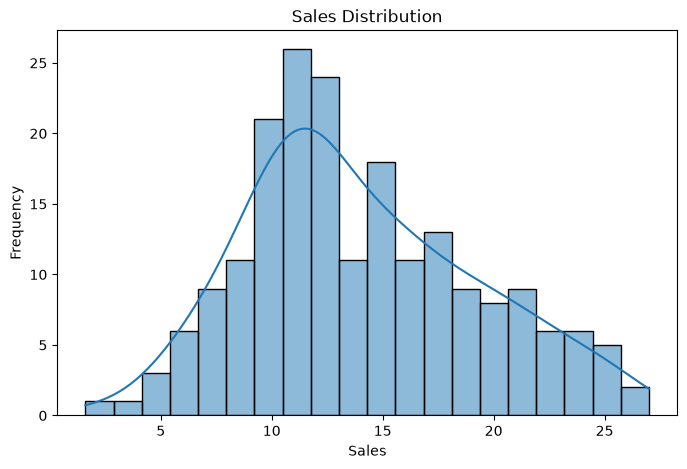

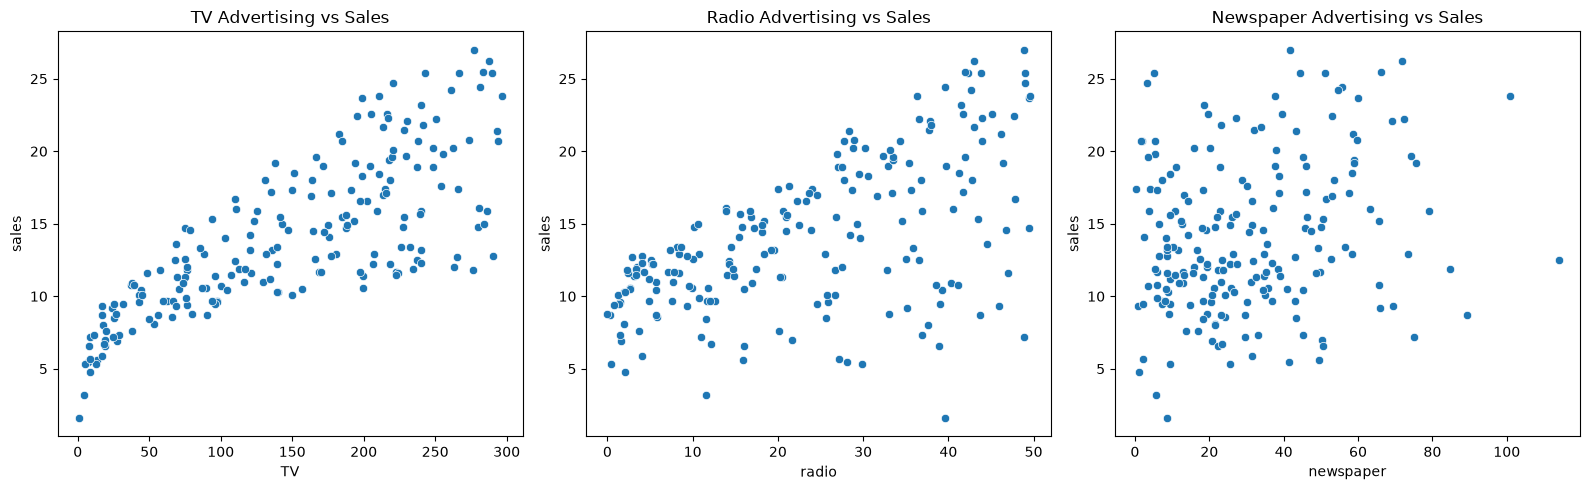

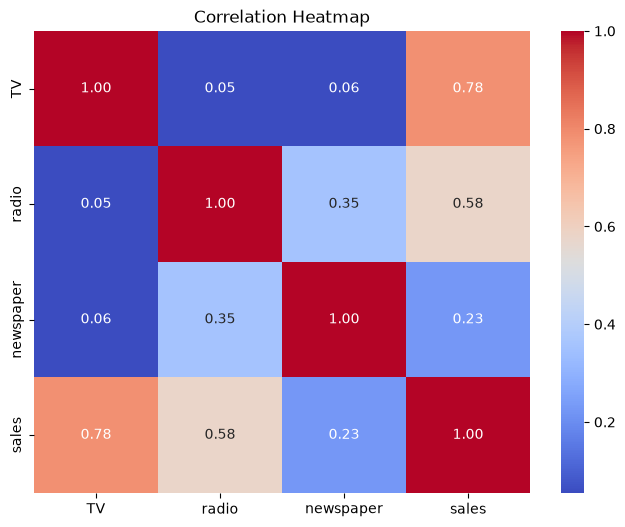

In [3]:
# Exploratory Data Analysis

# Sales Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["sales"], kde=True, bins=20)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

# Advertising Budget vs Sales
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.scatterplot(data=df, x="TV", y="sales", ax=axes[0])
axes[0].set_title("TV Advertising vs Sales")

sns.scatterplot(data=df, x="radio", y="sales", ax=axes[1])
axes[1].set_title("Radio Advertising vs Sales")

sns.scatterplot(data=df, x="newspaper", y="sales", ax=axes[2])
axes[2].set_title("Newspaper Advertising vs Sales")

plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [4]:
# Model Training and Evaluation

X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append([name, mae, rmse, r2])

    print("\nModel:", name)
    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))

results_df = pd.DataFrame(
    results, columns=["Model", "MAE", "RMSE", "R2 Score"]
)

display(results_df)


Model: Linear Regression
MAE: 1.4608
RMSE: 1.7816
R2 Score: 0.8994

Model: Random Forest
MAE: 0.6289
RMSE: 0.7577
R2 Score: 0.9818


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.460757,1.781600,0.899438
1,Random Forest,0.628925,0.757657,0.981813


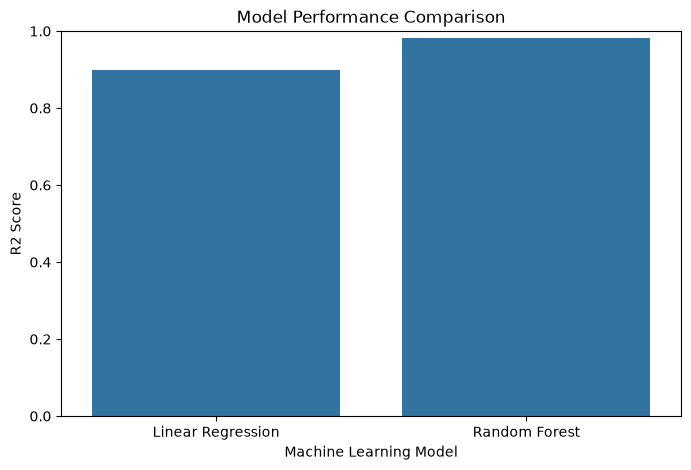

Best Performing Model: Random Forest


In [5]:
# Model Comparison

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("R2 Score")
plt.ylim(0, 1)
plt.show()

# Select Best Model
best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("Best Performing Model:", best_model_name)

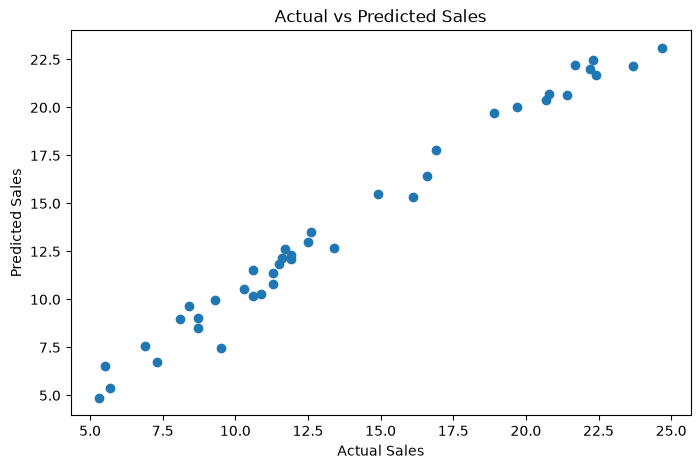

,Actual Sales,Predicted Sales
0,16.9,17.7650
1,22.4,21.6665
2,21.4,20.6550
3,7.3,6.7395
4,24.7,23.0960
5,12.6,13.5155
6,22.3,22.4860
7,8.4,9.6625
8,11.5,11.8545
9,14.9,15.5040


In [6]:
# Actual vs Predicted Sales

y_pred = best_model.predict(X_test)

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

# Prediction Results
prediction_results = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

display(prediction_results.head(10))

,Feature,Importance
0,TV,0.624729
1,radio,0.362129
2,newspaper,0.013142


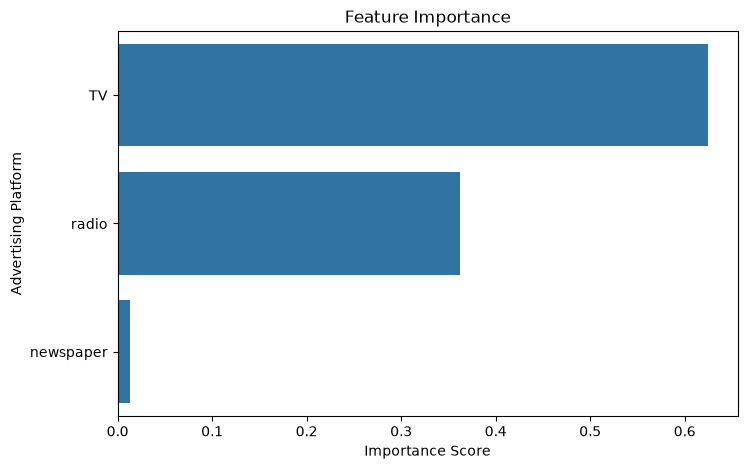

In [7]:
# Feature Importance

rf_model = models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

display(importance_df)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Advertising Platform")
plt.show()

In [8]:
# Predict Sales for New Advertising Budget

new_data = pd.DataFrame({
    "TV": [200],
    "radio": [40],
    "newspaper": [30]
})

new_prediction = best_model.predict(new_data)

print("New Advertising Budget:")
display(new_data)

print("Predicted Sales:", round(new_prediction[0], 2))

New Advertising Budget:


,TV,radio,newspaper
0,200,40,30


Predicted Sales: 20.4


In [9]:
# Project Conclusion

print("SALES PREDICTION PROJECT - CONCLUSION")
print("--------------------------------------")

print("Dataset: Advertising.csv")
print("Total Records:", len(df))
print("Features: TV, Radio, Newspaper")
print("Target Variable: Sales")

print("\nModels Used:")
print("1. Linear Regression")
print("2. Random Forest Regression")

print("\nBest Model:", best_model_name)

print("\nThis project predicts product sales based on advertising")
print("budgets using Machine Learning regression algorithms.")

print("\nProject Completed Successfully!")

SALES PREDICTION PROJECT - CONCLUSION
--------------------------------------
Dataset: Advertising.csv
Total Records: 200
Features: TV, Radio, Newspaper
Target Variable: Sales

Models Used:
1. Linear Regression
2. Random Forest Regression

Best Model: Random Forest

This project predicts product sales based on advertising
budgets using Machine Learning regression algorithms.

Project Completed Successfully!
